# 18 · Análisis exploratorio: entrenar con el 10 % de `CONTINUA`

**Etapa 23 del plan.** La cátedra de 2021 entrenaba con todas las bajas y solo el 10 % de los `CONTINUA` (*undersampling*). Cada modelo entrena con unas 9 veces menos filas. Si no pierde dinero, buscar hiperparámetros sobre el banco temporal pasa a ser barato.

**Pregunta:** ¿cuánto dinero cambia `ACH_4_P3`, la vigente del `15`, al entrenar con el 10 % de `CONTINUA`?

| Configuración | `CONTINUA` | Peso de `BAJA+2` | `min_data_in_leaf` | Para qué |
|---|---:|---:|---:|---|
| `ACH_4_P3` | 100 % | 3 | 764 | La referencia. Sus predicciones se leen del `15` |
| `ACH_4_P3_U10` | 10 % | 3 | 764 | **Esta decide** |
| `ACH_4_P1_U10` | 10 % | 1 | 764 | Si el peso triple todavía ayuda |
| `ACH_4_P3_U10_H` | 10 % | 3 | 76 | Si importa el tamaño de las hojas: con 76 filas, una hoja representa los mismos clientes que antes con 764 |

**La muestra:** entran todos los `BAJA+1` y `BAJA+2` de los meses de entrenamiento, y cada `CONTINUA` con probabilidad 0,10, sin repesar. Cambia con la semilla, y es la misma para las tres variantes y los cinco meses evaluados. El modelo predice a **todos** los clientes del mes evaluado.

Mismo banco temporal del `15`: para evaluar un mes, el modelo entrena con todos los meses desde 201903 hasta dos meses antes. Se evalúan 201906 a 201910, con 5 semillas, las columnas de `ACH_4` y 296 árboles.

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada. No carga 201911 ni 201912. **No escribe en `exp/03/` a `exp/17/` ni en los `resultados/03_*` a `17_*`:** solo los lee.

Ficha: `fichas/etapa_23_undersampling.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los modelos ya hechos no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_15 = Path('../exp/15')                          # solo se lee
EXP = Path('../exp/18')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_TABLA = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]
MESES_FINALES = [201909, 201910]
MESES_CONSIGNA = [201903, 201904, 201905, 201906]
ULTIMOS = 4
DISTANCIA = 2                                       # la clase de un mes se conoce dos meses después
MESES_TRAIN = MESES_CONSIGNA                        # los pide `construir`; acá cada modelo elige su ventana
MESES_EVAL = MESES_FINALES
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]   # como en el 06 y el 12

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
REFERENCIA = 'ACH_4_P3'                             # la vigente del 15: sus predicciones se leen de exp/15
FRACCION_CONTINUA = 0.10                            # como la cátedra 2021 (961_epic.r)
CONFIGS = {                                         # peso de BAJA+2, fracción de CONTINUA, min_data_in_leaf (None: el del 03)
    'ACH_4_P3_U10':   {'peso': 3, 'fraccion': FRACCION_CONTINUA, 'hoja': None},
    'ACH_4_P1_U10':   {'peso': 1, 'fraccion': FRACCION_CONTINUA, 'hoja': None},
    'ACH_4_P3_U10_H': {'peso': 3, 'fraccion': FRACCION_CONTINUA, 'hoja': 76},
}
CONFIG_REFERENCIA = {'peso': 3, 'fraccion': 1.0, 'hoja': None}
DECIDE = 'ACH_4_P3_U10'
CONTRASTES = [('ACH_4_P3_U10', REFERENCIA), ('ACH_4_P1_U10', REFERENCIA), ('ACH_4_P3_U10_H', REFERENCIA),
              ('ACH_4_P1_U10', 'ACH_4_P3_U10'), ('ACH_4_P3_U10_H', 'ACH_4_P3_U10')]
HIPOTESIS = {
    'ACH_4_P3_U10': 'Con el 10 % de CONTINUA, ACH_4_P3 no pierde dinero',
    'ACH_4_P1_U10': 'Con el 10 % de CONTINUA, el peso triple de BAJA+2 ya no hace falta',
    'ACH_4_P3_U10_H': 'Con el 10 % de CONTINUA, hojas de 76 filas representan los mismos clientes que las de 764',
}
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
FOTOS = 9                                           # 201910 llega hasta 201901

N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_TABLA = (1_037_551, 5_042)                 # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[01234567]_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 48


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook. La clase de 201911 y 201912 nunca se carga.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

Dataset cargado en 2 s


## 3. Tablas de `ACH_4`

Las mismas columnas de `ACH_4` del `15`: 1.180, el baseline más la historia curada y los cuatro bloques del `14`.

**Control 4:** una columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_TABLA)
assert T['F'].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_TABLA[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Tablas y controles 4 y 6 OK en 25 s · memoria máxima 4.7 GB


## 4. Muestras, ventanas y controles

**Control 3:** ningún modelo entrena con un mes posterior a dos meses antes del evaluado.

**Control 5:** con el 100 % de `CONTINUA`, `ACH_4_P3` de 201906 y la primera semilla da la predicción del `15`. Comprueba que este notebook entrena igual que el `15`: lo único que cambia en las variantes es la muestra, el peso o el tamaño de hoja.

**Control 11:** las columnas son las 1.180 de `ACH_4`, sin nombres repetidos.

**Control 12:** cada muestra tiene todas las bajas de los meses de entrenamiento y entre el 9,5 % y el 10,5 % de los `CONTINUA` de cada mes. Cambia con la semilla, y las tres variantes usan la misma.

In [4]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
assert ARBOLES == 296 and MEJORES['min_data_in_leaf'] == 764
assert CONFIGS['ACH_4_P3_U10_H']['hoja'] == round(MEJORES['min_data_in_leaf'] * FRACCION_CONTINUA)
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}
TODAS_CONFIGS = [REFERENCIA, *CONFIGS]
PARAMS = {REFERENCIA: CONFIG_REFERENCIA, **CONFIGS}

CLASE_T = CLASE[T['filas']]
ES_B2 = CLASE_T == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_TABLA}
ENTRENA = {m: [x for x in MESES_TABLA if x <= m - DISTANCIA] for m in MESES_EVALUADOS}
assert all(ENTRENA[m] and max(ENTRENA[m]) <= m - DISTANCIA for m in MESES_EVALUADOS)        # control 3
MESES_ENTRENAMIENTO = sorted({x for m in MESES_EVALUADOS for x in ENTRENA[m]})
assert set(np.unique(CLASE_T[np.isin(T['mes_fila'], MESES_ENTRENAMIENTO)])) == {'CONTINUA', 'BAJA+1', 'BAJA+2'}


def muestrear(semilla):
    """Filas de la tabla que pueden entrar al entrenamiento con esa semilla: todas las bajas y el 10 % de CONTINUA."""
    u = np.random.default_rng([SEMILLA_PRIMIGENIA, semilla]).random(len(T['filas']))
    return (CLASE_T != 'CONTINUA') | (u < FRACCION_CONTINUA)


MUESTRA = {s: muestrear(s) for s in SEMILLAS}


def filas_entrena(config, mes, semilla):
    entrena = np.isin(T['mes_fila'], ENTRENA[mes])
    if PARAMS[config]['fraccion'] < 1:
        entrena &= MUESTRA[semilla]
    return entrena


def ruta(config, mes, semilla, que='pred'):
    return EXP / que / config / str(mes) / f'{semilla}.npy'


def tabla_de(filas):
    k = ESPERADO_N_VARIABLES[BASE_CURADA]
    X = np.hstack([T['F'][filas, :k]] + [B[b][0][filas] for b in CANDIDATAS])
    return X, T['columnas'][:k] + [c for b in CANDIDATAS for c in B[b][1]]


def dataset(config, mes, semilla):
    entrena = filas_entrena(config, mes, semilla)
    X, columnas = tabla_de(entrena)
    clase = CLASE_T[entrena]
    d = lgb.Dataset(X, label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=columnas, params=BINS, free_raw_data=True).construct()
    d.set_weight(np.where(clase == 'BAJA+2', PARAMS[config]['peso'], 1).astype(np.float32))
    del X
    return d, int(entrena.sum())


def entrenar(dtrain, semilla, config):
    hoja = PARAMS[config]['hoja']
    extra = {} if hoja is None else {'min_data_in_leaf': hoja}
    return lgb.train({**MEJORES, **extra, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA}, dtrain, num_boost_round=ARBOLES)


# Control 12: la muestra
for s in SEMILLAS:
    assert MUESTRA[s][CLASE_T != 'CONTINUA'].all()
    for x in MESES_ENTRENAMIENTO:
        parte = MUESTRA[s][(CLASE_T == 'CONTINUA') & es_mes[x]].mean()
        assert 0.095 <= parte <= 0.105, (s, x, parte)
assert all((MUESTRA[a] != MUESTRA[b]).any() for a in SEMILLAS for b in SEMILLAS if a < b)
for m in MESES_EVALUADOS:
    for s in SEMILLAS:
        f = [filas_entrena(c, m, s) for c in CONFIGS]
        assert all(np.array_equal(f[0], g) for g in f[1:]), (m, s)
        assert not (f[0] & ~np.isin(T['mes_fila'], ENTRENA[m])).any()
        assert filas_entrena(REFERENCIA, m, s).sum() == np.isin(T['mes_fila'], ENTRENA[m]).sum()

FILAS = pd.DataFrame({'meses de entrenamiento': {m: f'{ENTRENA[m][0]}-{ENTRENA[m][-1] % 100:02d}' for m in MESES_EVALUADOS},
                      'filas, 100 %': {m: int(filas_entrena(REFERENCIA, m, SEMILLAS[0]).sum()) for m in MESES_EVALUADOS},
                      'filas, muestra (media de semillas)': {m: round(np.mean([filas_entrena(DECIDE, m, s).sum() for s in SEMILLAS])) for m in MESES_EVALUADOS}})
FILAS['parte'] = (FILAS['filas, muestra (media de semillas)'] / FILAS['filas, 100 %']).round(3)
print(FILAS.to_string())

# Control 11
COLUMNAS = tabla_de(np.arange(2))[1]
assert len(COLUMNAS) == len(set(COLUMNAS)) == ESPERADO_N_VARIABLES[JUNTAS]

# Control 5
ruta_control = EXP / 'control_5.txt'
if not ruta_control.exists():
    t0 = time.time()
    dtrain, _ = dataset(REFERENCIA, 201906, SEMILLAS[0])
    modelo = entrenar(dtrain, SEMILLAS[0], REFERENCIA)
    prob = modelo.predict(tabla_de(es_mes[201906])[0], num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_15 / 'pred' / REFERENCIA / '201906' / f'{SEMILLAS[0]}.npy')), 'ACH_4_P3 no reproduce el 15'
    ruta_control.parent.mkdir(parents=True, exist_ok=True)
    ruta_control.write_text(f'ok\nsegundos_201906 {time.time() - t0:.1f}\n')
    del dtrain, modelo, prob
    gc.collect()
    print(f'Control 5 OK en {time.time() - t0:.0f} s (un modelo de ACH_4_P3 con todas las filas de 201903-04)')
else:
    print('Control 5 ya hecho')
print('Controles 3, 11 y 12 OK')

       meses de entrenamiento  filas, 100 %  filas, muestra (media de semillas)  parte
201906              201903-04        251738                               27744  0.110
201907              201903-05        378501                               41564  0.110
201908              201903-06        506871                               55484  0.109
201909              201903-07        636724                               69642  0.109
201910              201903-08        768499                               83947  0.109
Control 5 OK en 26 s (un modelo de ACH_4_P3 con todas las filas de 201903-04)
Controles 3, 11 y 12 OK


## 5. Modelos

Un modelo por configuración, mes y semilla, con 296 árboles. La referencia no se entrena: se leen sus predicciones del `15`. Cada modelo predice a todos los clientes del mes evaluado.

**Retomar:** cada predicción se guarda al terminar el modelo, junto con sus segundos (armar el dataset y entrenar).

**Control 7:** cada configuración tiene predicción para cada mes y semilla, sobre todos los clientes del mes.

In [5]:
falta = lambda c, m, s: not ruta(c, m, s).exists()
print('Modelos pendientes:', sum(falta(c, m, s) for c in CONFIGS for m in MESES_EVALUADOS for s in SEMILLAS))
for m in MESES_EVALUADOS:
    pendientes = [(c, s) for c in CONFIGS for s in SEMILLAS if falta(c, m, s)]
    if not pendientes:
        continue
    X_mes = tabla_de(es_mes[m])[0]
    segundos = {}
    for c, s in pendientes:
        t0 = time.time()
        dtrain, n = dataset(c, m, s)
        modelo = entrenar(dtrain, s, c)
        prob = modelo.predict(X_mes, num_threads=N_HILOS).astype(np.float32)
        seg = time.time() - t0
        for que, valor in (('pred', prob), ('seg', np.array([seg, n], dtype=np.float64))):
            destino = ruta(c, m, s, que)
            assert destino.is_relative_to(EXP), destino
            destino.parent.mkdir(parents=True, exist_ok=True)
            np.save(destino, valor)
        segundos.setdefault(c, []).append(seg)
        del dtrain, modelo
    print(f'{m}: ' + ' · '.join(f'{c} {np.mean(v):.0f} s' for c, v in segundos.items()) + f' por modelo · memoria máxima {memoria_gb()} GB', flush=True)
    del X_mes
    gc.collect()

leer = lambda c, m, s: np.load(EXP_15 / 'pred' / REFERENCIA / str(m) / f'{s}.npy') if c == REFERENCIA else np.load(ruta(c, m, s))
PUNTAJE = {(c, m): np.stack([leer(c, m, s) for s in SEMILLAS]) for c in TODAS_CONFIGS for m in MESES_EVALUADOS}
assert all(v.shape == (N_SEMILLAS, es_mes[k[1]].sum()) and not np.isnan(v).any() for k, v in PUNTAJE.items())   # control 7
print('Predicciones completas:', len(PUNTAJE), 'grupos de', N_SEMILLAS, 'semillas')

Modelos pendientes: 75
201906: ACH_4_P3_U10 4 s · ACH_4_P1_U10 4 s · ACH_4_P3_U10_H 6 s por modelo · memoria máxima 4.7 GB
201907: ACH_4_P3_U10 6 s · ACH_4_P1_U10 6 s · ACH_4_P3_U10_H 7 s por modelo · memoria máxima 4.7 GB
201908: ACH_4_P3_U10 8 s · ACH_4_P1_U10 8 s · ACH_4_P3_U10_H 9 s por modelo · memoria máxima 4.7 GB
201909: ACH_4_P3_U10 11 s · ACH_4_P1_U10 11 s · ACH_4_P3_U10_H 11 s por modelo · memoria máxima 5.0 GB
201910: ACH_4_P3_U10 13 s · ACH_4_P1_U10 13 s · ACH_4_P3_U10_H 13 s por modelo · memoria máxima 5.0 GB
Predicciones completas: 20 grupos de 5 semillas


## 6. Comparaciones y costo

**Medida:** ganancia en la banda de 3.000 a 6.000 envíos, para cada mes y semilla. Después se promedian los meses y las semillas.

**Error total:** suma el ruido de clientes y el de semilla, como en el `15`.
- **De clientes:** bootstrap pareado. Cada cliente aporta lo que deja en todos sus meses, y se remuestrean clientes, no filas.
- **De semilla:** un desvío común, estimado con las dos configuraciones de cada comparación. Incluye el azar de la muestra.

El intervalo es la diferencia más o menos 1,96 errores totales.

**Costo:** filas de entrenamiento y segundos por modelo (armar el dataset y entrenar), por configuración y mes.

In [6]:
B_MES = {(c, m): np.array([banda(curva(p, ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[(c, m)]]) for c, m in PUNTAJE}
filas = [{'config': c, 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(c, m)][i], 4),
          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[(c, m)][i]), 6)}
         for c, m in PUNTAJE for i, s in enumerate(SEMILLAS)]
meses_tabla = pd.DataFrame(filas)
meses_tabla.to_csv(RESULTADOS / '18_meses.csv', index=False)

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(config):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in MESES_EVALUADOS:
        idx = np.flatnonzero(es_mes[m])
        for p in PUNTAJE[(config, m)]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            aporte = PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
            np.add.at(v, POS_CLIENTE[idx[orden]], aporte)
    return v / (len(MESES_EVALUADOS) * N_SEMILLAS)


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


por_semilla = lambda c: np.mean([B_MES[(c, m)] for m in MESES_EVALUADOS], axis=0)
ensamble = lambda c: float(np.mean([banda(curva(PUNTAJE[(c, m)].mean(axis=0), ES_B2[es_mes[m]])) / 1e6 for m in MESES_EVALUADOS]))
APORTE = {c: por_cliente(c) for c in TODAS_CONFIGS}

filas = []
for j, (c, contra) in enumerate(CONTRASTES):
    d_cliente = APORTE[c] - APORTE[contra]
    d = d_cliente.sum() / 1e6
    assert abs(d - (por_semilla(c).mean() - por_semilla(contra).mean())) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + j) / 1e6).std()
    desvio = np.sqrt((por_semilla(c).var(ddof=1) + por_semilla(contra).var(ddof=1)) / 2)
    e_s = desvio * np.sqrt(2 / N_SEMILLAS)
    e_t = float(np.hypot(e_c, e_s))
    filas.append({'config': c, 'contra': contra, 'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s, 'error_total_M': e_t,
                  'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t, 'd_ensamble_M': ensamble(c) - ensamble(contra),
                  'semillas_a_favor': int((por_semilla(c) > por_semilla(contra)).sum()),
                  **{f'd_{m}': B_MES[(c, m)].mean() - B_MES[(contra, m)].mean() for m in MESES_EVALUADOS}})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '18_comparacion.csv', index=False)

SEG = {(c, m, s): np.load(ruta(c, m, s, 'seg')) for c in CONFIGS for m in MESES_EVALUADOS for s in SEMILLAS}
assert all(int(v[1]) == filas_entrena(c, m, s).sum() for (c, m, s), v in SEG.items())
costo = pd.DataFrame([{'config': c, 'foto_mes': m, 'filas_entrenamiento': round(np.mean([SEG[(c, m, s)][1] for s in SEMILLAS])),
                       'segundos_por_modelo': round(np.mean([SEG[(c, m, s)][0] for s in SEMILLAS]), 1)}
                      for c in CONFIGS for m in MESES_EVALUADOS])
costo = pd.concat([pd.DataFrame([{'config': REFERENCIA, 'foto_mes': m, 'filas_entrenamiento': int(FILAS.loc[m, 'filas, 100 %']),
                                  'segundos_por_modelo': np.nan} for m in MESES_EVALUADOS]), costo], ignore_index=True)
costo.to_csv(RESULTADOS / '18_costo.csv', index=False)

print('EXPLORATORIO')
print(comparacion.round(2).to_string(index=False))
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({c: {m: B_MES[(c, m)].mean() for m in MESES_EVALUADOS} for c in TODAS_CONFIGS}).T.round(2).to_string())
print()
print('AUC por mes (media de semillas):')
print(meses_tabla.groupby(['config', 'foto_mes'])['auc'].mean().unstack().loc[TODAS_CONFIGS].round(4).to_string())
print()
print('Costo: filas de entrenamiento y segundos por modelo (armar el dataset y entrenar).')
print('La referencia se entrenó en el 15; el control 5 da su tiempo en 201906.')
print(costo.pivot(index='config', columns='foto_mes', values='filas_entrenamiento').loc[TODAS_CONFIGS].to_string())
print(costo.pivot(index='config', columns='foto_mes', values='segundos_por_modelo').loc[list(CONFIGS)].to_string())
print((EXP / 'control_5.txt').read_text())

EXPLORATORIO
        config       contra   d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d_ensamble_M  semillas_a_favor  d_201906  d_201907  d_201908  d_201909  d_201910
  ACH_4_P3_U10     ACH_4_P3 -9.56              1.67             0.45           1.73      -12.95       -6.16         -9.82                 0    -26.41     -8.82     -5.21     -3.19     -4.15
  ACH_4_P1_U10     ACH_4_P3 -8.70              1.67             0.48           1.74      -12.11       -5.28         -8.72                 0    -24.69     -7.66     -6.89     -5.44      1.20
ACH_4_P3_U10_H     ACH_4_P3 -2.57              1.05             0.50           1.16       -4.85       -0.29         -2.10                 0     -6.79     -2.41      0.21     -2.11     -1.77
  ACH_4_P1_U10 ACH_4_P3_U10  0.86              0.91             0.53           1.05       -1.21        2.92          1.10                 4      1.72      1.16     -1.68     -2.25      5.34
ACH_4_P3_U10_H ACH_4_P3_U10  6.98    

## 7. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

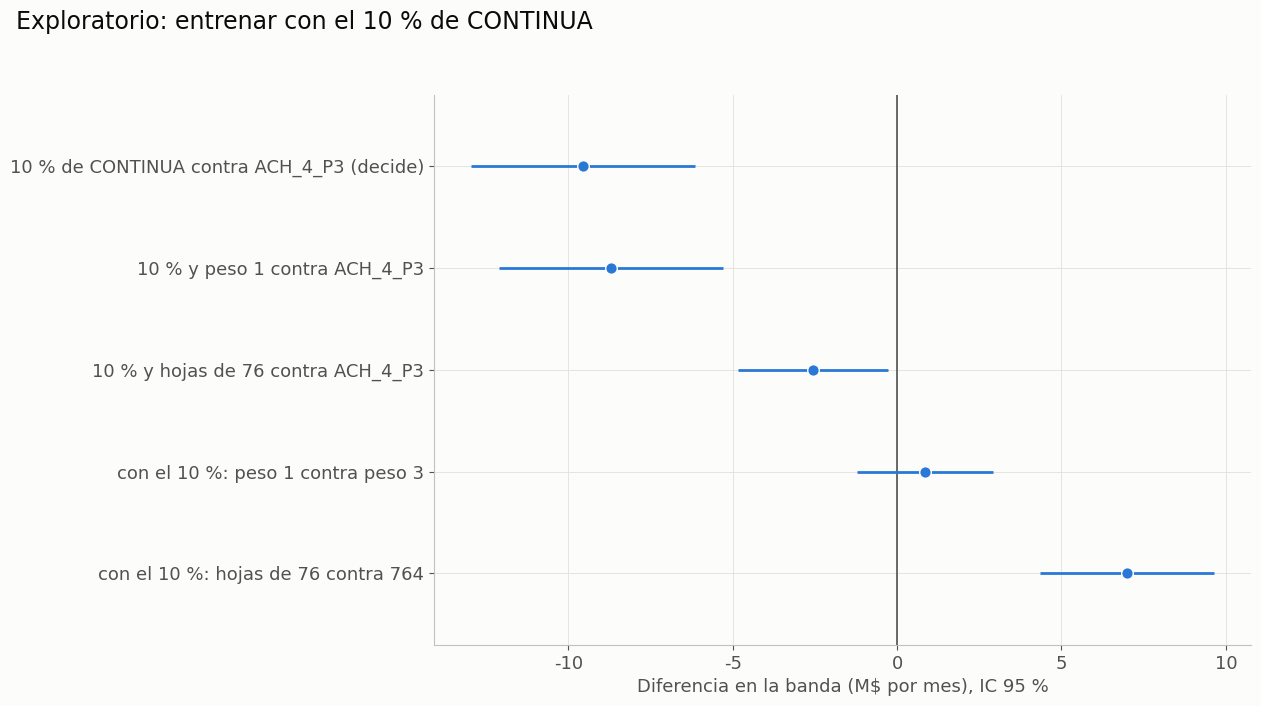

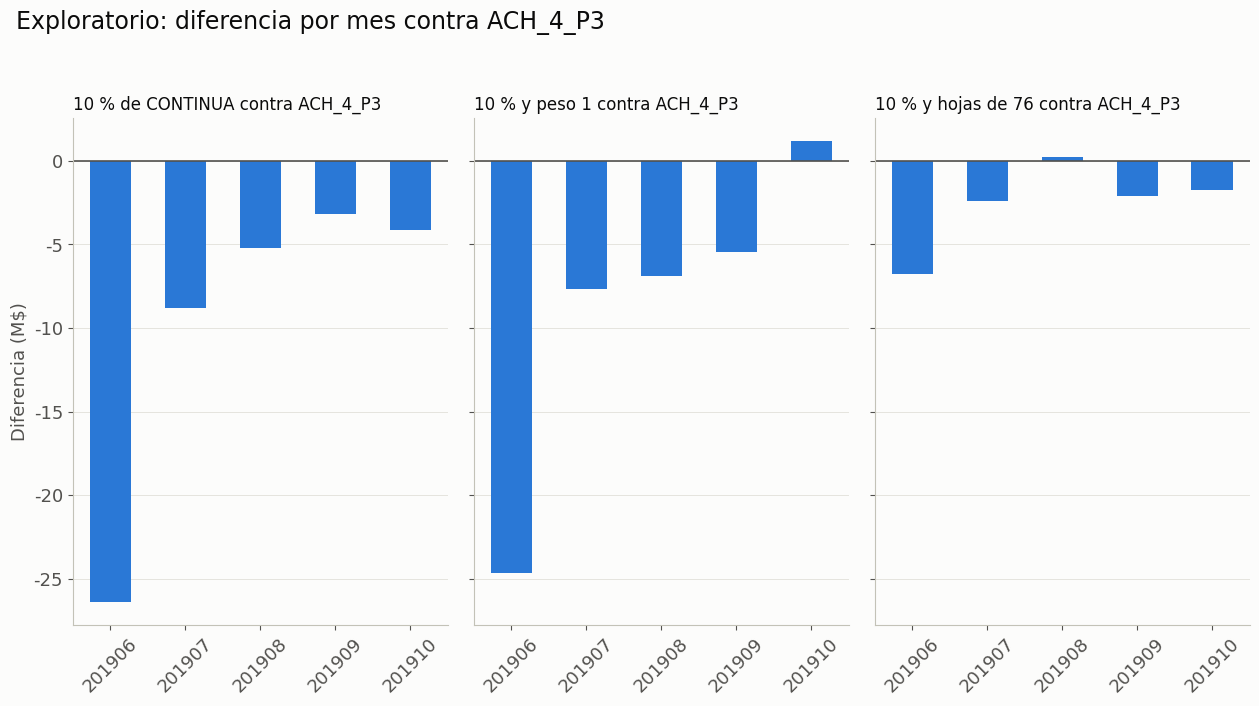

In [7]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


NOMBRES = {('ACH_4_P3_U10', REFERENCIA): '10 % de CONTINUA contra ACH_4_P3 (decide)',
           ('ACH_4_P1_U10', REFERENCIA): '10 % y peso 1 contra ACH_4_P3',
           ('ACH_4_P3_U10_H', REFERENCIA): '10 % y hojas de 76 contra ACH_4_P3',
           ('ACH_4_P1_U10', 'ACH_4_P3_U10'): 'con el 10 %: peso 1 contra peso 3',
           ('ACH_4_P3_U10_H', 'ACH_4_P3_U10'): 'con el 10 %: hojas de 76 contra 764'}
t = comparacion.set_index(['config', 'contra'])
orden = list(CONTRASTES)
y = np.arange(len(orden))[::-1]
formato = FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1))

fig, ax = plt.subplots(figsize=TAMANO)
ax.axvline(0, color=TINTA_2, lw=1.2)
ax.hlines(y, t.loc[orden, 'ic95_inf_M'], t.loc[orden, 'ic95_sup_M'], color=AZUL, lw=2)
ax.scatter(t.loc[orden, 'd_M'], y, s=70, color=AZUL, zorder=3, edgecolor='#fcfcfb')
ax.set_yticks(y, [NOMBRES[k] for k in orden])
ax.set_ylim(-0.7, len(orden) - 0.3)
ax.xaxis.set_major_formatter(formato)
ax.set_xlabel('Diferencia en la banda (M$ por mes), IC 95 %')
fig.suptitle('Exploratorio: entrenar con el 10 % de CONTINUA', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '18_1_undersampling.png', dpi=DPI)
plt.show()

orden_mes = orden[:3]
fig, ejes = plt.subplots(1, len(orden_mes), figsize=TAMANO, sharey=True)
for ax, k in zip(ejes, orden_mes):
    ax.axhline(0, color=TINTA_2, lw=1.2)
    ax.bar([str(m) for m in MESES_EVALUADOS], [t.loc[k, f'd_{m}'] for m in MESES_EVALUADOS], color=AZUL, width=0.55)
    ax.yaxis.set_major_formatter(formato)
    ax.set_title(NOMBRES[k].replace(' (decide)', ''), loc='left', fontsize=12, wrap=True)
    ax.tick_params(axis='x', labelrotation=45)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(True)
ejes[0].set_ylabel('Diferencia (M$)')
fig.suptitle('Exploratorio: diferencia por mes contra ACH_4_P3', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '18_2_por_mes.png', dpi=DPI)
plt.show()

## 8. Lectura fijada antes de correr

Decide solo `ACH_4_P3_U10` contra `ACH_4_P3`, con `d` = la diferencia media en la banda:

| `d` | Lectura |
|---|---|
| +1 M o más | Suma: `ACH_4_P3_U10` pasa a ser la vigente |
| Entre −1 y +1 M | Empate: queda `ACH_4_P3`. El *undersampling* queda habilitado para buscar hiperparámetros |
| −1 M o menos | Resta: queda `ACH_4_P3`. Una búsqueda con *undersampling* tendría que evaluar entrenando igual que busca |

Las otras cuatro comparaciones explican de dónde viene la diferencia, pero no deciden. Si `ACH_4_P3_U10_H` sale arriba, es una pista para la búsqueda de hiperparámetros, no la nueva vigente. El intervalo se informa siempre.

**Control 8:** las salidas anteriores no cambiaron.

In [8]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 8
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

lectura = lambda d: 'Suma' if d >= UMBRAL else ('Resta' if d <= -UMBRAL else 'Empate')
for r in comparacion.itertuples():
    marca = ' · DECIDE' if (r.config, r.contra) == (DECIDE, REFERENCIA) else ''
    print(f'{r.config} contra {r.contra}: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · error {r.error_total_M:.2f} M · '
          f'ensamble {r.d_ensamble_M:+.2f} M · semillas a favor {r.semillas_a_favor} de {N_SEMILLAS} · {lectura(r.d_M)}{marca}')

t = comparacion.set_index(['config', 'contra'])
pd.DataFrame([{'config': c, 'hipotesis': HIPOTESIS[c], 'contra': REFERENCIA, **{k: v for k, v in CONFIGS[c].items()},
               'd_M': round(t.loc[(c, REFERENCIA), 'd_M'], 3), 'resultado': lectura(t.loc[(c, REFERENCIA), 'd_M']),
               'decide': c == DECIDE} for c in CONFIGS]).to_csv(RESULTADOS / '18_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 11.8 min en total · memoria máxima 5.0 GB

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

ACH_4_P3_U10 contra ACH_4_P3: -9.56 M (-12.95 a -6.16) · error 1.73 M · ensamble -9.82 M · semillas a favor 0 de 5 · Resta · DECIDE
ACH_4_P1_U10 contra ACH_4_P3: -8.70 M (-12.11 a -5.28) · error 1.74 M · ensamble -8.72 M · semillas a favor 0 de 5 · Resta
ACH_4_P3_U10_H contra ACH_4_P3: -2.57 M (-4.85 a -0.29) · error 1.16 M · ensamble -2.10 M · semillas a favor 0 de 5 · Resta
ACH_4_P1_U10 contra ACH_4_P3_U10: +0.86 M (-1.21 a 2.92) · error 1.05 M · ensamble +1.10 M · semillas a favor 4 de 5 · Empate
ACH_4_P3_U10_H contra ACH_4_P3_U10: +6.98 M (4.33 a 9.64) · error 1.35 M · ensamble +7.72 M · semillas a favor 5 de 5 · Suma
